### PART 1 : Importing Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42


### PART 2: Loading csv file

In [2]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
df.head()
print("Shape:", df.shape)
print()
df.info()

Shape: (320, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AdvertisingSpend_KES  320 non-null    int64 
 1   StoreVisits           320 non-null    int64 
 2   DiscountPercent       320 non-null    int64 
 3   Region                320 non-null    object
 4   CustomerSegment       320 non-null    object
 5   ProductCategory       320 non-null    object
 6   Sales_KES             320 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.6+ KB


1.The dataset contains 320 rows and 7 columns with each row representing one sales observation. 

2.There are four numerical variables which are AdvertisingSpend_KES, StoreVisits, DiscountPercent and Sales_KES. 
The three categorical variables are Region, CustomerSegment and ProductCategory.

3.The target variable is Sales_KES while the six remaining variables are the features used to predict sales.

### PART 3 : Data Audit 

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


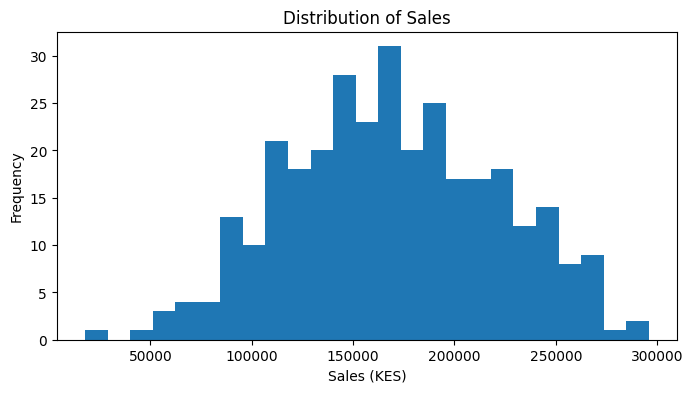

In [3]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
df["Sales_KES"].describe()
plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

1.Sales range from KES 17,805 to KES 295,825, with an average of KES 169,252.45. 

2.The histogram shows a roughly symmetric bell-shaped distribution. 

3.Although some sales values are very low or high, they appear to be part of the normal data range so they should not be removed automatically.

### Part 4: Define the Analytical Task

The objective is to predict sales revenue (`Sales_KES`) using advertising spending, store visits, discount percentage, region, customer segment and product category. Since sales revenue is a continuous numerical variable, this is a supervised regression problem. The model will learn patterns from historical data to predict sales for new observations.

### PART 5 : Separate Features and Target

In [4]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


### PART 6 : Train/Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


### PART 7 : Identifying feature types

In [6]:
numeric_features = [
    "AdvertisingSpend_KES",
    "StoreVisits",
    "DiscountPercent"
]
categorical_features = [
    "Region",
    "CustomerSegment",
    "ProductCategory"
]

### PART 8 : Leakage safe preprocessing

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

### PART 9 : Building Baselines

In [8]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")
mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)
mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

### PART 10 : Evaluation metrics


In [9]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
        "R2": [r2_score(y_true, y_pred)]
})
mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")
pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


### PART 11 : Linear Regression

In [10]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
linear_results = evaluate_regression(
    y_test, linear_pred, "Linear Regression"
)
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


### Interpretation: Linear Regression

The Linear Regression model has an MAE of KES 13,757.84 and an RMSE of KES 17,469.69, both lower than the mean and median baselines. Its R² score of 0.8703 is also higher than both baseline scores, which are negative. This shows that Linear Regression predicts sales more accurately than simply using the mean or median sales value. Therefore, the model adds useful predictive value.

### PART 12 : Ridge regression

In [11]:
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_results = evaluate_regression(
    y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


### PART 13 : Shallow Decision trees

In [12]:
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
min_samples_leaf=8,
        random_state=RANDOM_STATE
    ))
])
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_results = evaluate_regression(
    y_test, tree_pred, "Decision Tree"
)
tree_results
 

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


### PART 14 : Comparing all Models

In [13]:
comparison = pd.concat([
    mean_results,
    median_results,
    linear_results,
    ridge_results,
    tree_results
], ignore_index=True)
comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


### Interpretation: Model Comparison

Ridge Regression has the lowest MAE of KES 13,714.40 and the lowest RMSE of KES 17,458.82. It also has the highest R² score of 0.8705, meaning it explains approximately 87.05% of the variation in sales in the test data. Therefore, Ridge Regression is the best-performing model among the five models compared. Linear Regression performs almost as well, while the Decision Tree performs less accurately. Both the mean and median baselines perform poorly with negative R² scores. Although Ridge Regression is the strongest candidate based on these test metrics, the table alone is not enough to make a final decision because we also need to consider cross-validation results, residual patterns and subgroup perfomance

### PART 15 : Cross-validation on Training data

In [14]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model
}
rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=5,
        scoring=scoring
    )
    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })
cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


### Interpretation: Cross-Validation

Ridge Regression performs best, with the lowest MAE and RMSE and the highest R². Linear Regression performs almost as well, while the Decision Tree performs worse. These results are consistent with the test results, suggesting Ridge Regression is the strongest candidate. Cross-validation helps assess model consistency using different training data folds without repeatedly checking the final test set.

### PART 16 : Residual plotting


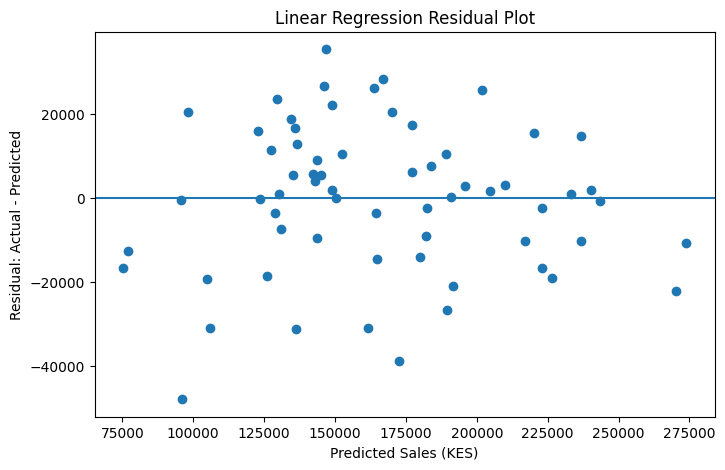

In [15]:
residuals = y_test - linear_pred
residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_pred,
    "Residual": residuals.values
})
residual_df.head()
plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

### Interpretation: Linear Regression Residual Plot

The residuals are scattered around zero with no clear pattern. However, a few large residuals may indicate potential outliers where the model makes less accurate predictions.

### PART 17 : Actual vs Predicted

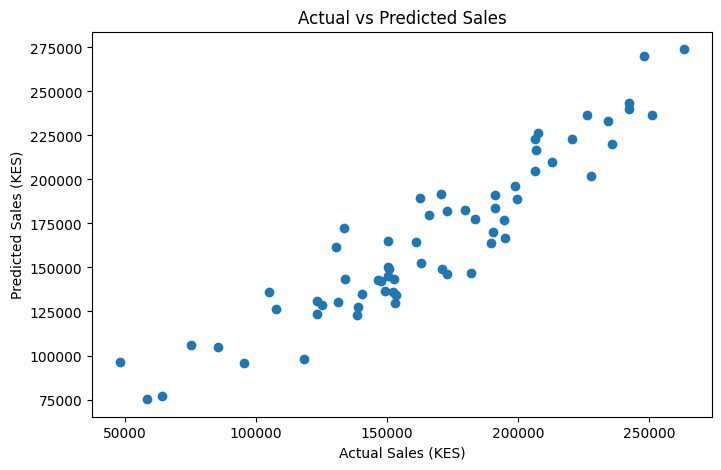

In [16]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

The points lie close to the diagonal line indicating that the model predicts sales well overall, with a few prediction errors.

### PART 18 : Inspecting Largest Errors

In [17]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()
error_analysis.sort_values(
    "AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


The largest prediction errors occur across different regions, segments, and product categories, suggesting that additional factors such as seasonality, competitor prices and customer demand could improve predictions.

### PART 19 : Error by Customer Segment

In [18]:
segment_errors = error_analysis.groupby(
    "CustomerSegment"
).agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean")
).reset_index()
segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


### Interpretation: Error by Customer Segment

Retail has the highest MAE (KES 15,560.58), while SME has the lowest (KES 10,481.46). The sample sizes are relatively similar ranging from 18 to 27 observations. Subgroup analysis helps identify segments where predictions are less accurate even when the overall MAE looks acceptable.

### PART 20 : Check for Overfitting

In [19]:
tree_train_pred = tree_model.predict(X_train)
print(
    "Shallow Tree Training MAE:",
round(mean_absolute_error(y_train, tree_train_pred), 2)
)
print(
    "Shallow Tree Test MAE:",
    round(mean_absolute_error(y_test, tree_pred), 2)
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


### PART 21 : Demonstrate an Overly deep Decision Tree

In [20]:
 
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ))
])
deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)
print(
    "Deep Tree Training MAE:",
    round(mean_absolute_error(y_train, deep_train_pred), 2)
)
print(
    "Deep Tree Test MAE:",
    round(mean_absolute_error(y_test, deep_test_pred), 2)
)



Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


An almost-perfect training result indicates overfitting where the model memorizes the training data instead of learning general patterns. This leads to poorer predictions on unseen data as shown by the higher test MAE.

### PART 22 : Extension Challenge

In [21]:
# Ridge Alpha Tuning
alpha_results = []

for alpha in [0.1, 1, 10, 100]:
    ridge_model = Pipeline([
        ("preprocess", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    ridge_model.fit(X_train, y_train)
    ridge_pred = ridge_model.predict(X_test)

    results = evaluate_regression(
        y_test, ridge_pred, f"Ridge alpha={alpha}"
    )

    alpha_results.append(results)

alpha_comparison = pd.concat(alpha_results, ignore_index=True)
alpha_comparison.sort_values(by="MAE")

,Model,MAE,RMSE,R2
2,Ridge alpha=10,13624.901530,17543.877079,0.869223
1,Ridge alpha=1,13714.400361,17458.820721,0.870488
0,Ridge alpha=0.1,13753.355349,17468.377537,0.870346
3,Ridge alpha=100,16922.745379,22593.657194,0.783103


Ridge with alpha = 10 has the lowest MAE (KES 13,624.90), while alpha = 1 has the lowest RMSE and highest R². Alpha = 100 performs worst, suggesting that excessive regularization reduces predictive performance. Alpha = 10 is preferred if minimizing average absolute error is the main goal

### PART 23 : Final Recommendation

1. The median baseline was slightly stronger than the mean baseline because it had a lower MAE, RMSE and a less negative R².

2. Ridge Regression with alpha = 10 performed best when minimizing MAE, achieving an MAE of KES 13,624.90.

3. Yes, Ridge Regression clearly outperformed the baselines, which had MAEs of approximately KES 39,000 and negative R² values.

4. MAE shows the average amount by which the model’s sales predictions differ from actual sales, helping a business understand how accurate its sales forecasts are and how much prediction error to expect.

5. Residual analysis showed that errors were generally scattered around zero, although some predictions had large errors.

6. Yes, performance differed by customer segment with Retail having the highest MAE and SME the lowest.

7. The deep Decision Tree showed evidence of overfitting because its training MAE was 0.0 while its test MAE was much higher at KES 26,797.50.

8. I would not deploy the model immediately because it needs further validation on new data and could benefit from additional predictors such as seasonality and customer demand.

### PART 24 : Limitations

1.The dataset contains only 320 observations which may not fully represent real-world sales patterns.

2.The model uses limited predictors and excludes factors such as seasonality, competitor prices and changing customer demand.

3.Sales patterns may change over time meaning the model's predictions may become less accurate when new data becomes available.

4.The model identifies relationships between variables but does not prove that advertising spend, discounts or other predictors directly cause changes in sales.